<a href="https://colab.research.google.com/github/naylanara89/ProyekAkhir_A_Avocado/blob/main/notebook/P12C_Varian2_Penyetelan_kNN_Avocado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 12C — Varian 2: Penyetelan Parameter k-NN
## Dikerjakan oleh anggota 2

Pembelajaran Mesin INF62325 · S1 Informatika · UIN Siber Syekh Nurjati Cirebon

### Kedudukan varian ini

Varian 1 menjalankan k-NN dengan parameter bawaan. Varian 2 menjawab pertanyaan
lanjutannya: **seberapa jauh algoritma yang sama bisa diperbaiki hanya dengan
menyetel parameternya, tanpa berganti algoritma.**

Jawabannya bisa saja mengecewakan. Kalau kenaikannya tipis, itu temuan yang sah dan
wajib dilaporkan apa adanya; menyetel parameter tidak dijamin membawa perbaikan besar.

### Luaran yang dikumpulkan

| Luaran | Bentuk |
| --- | --- |
| Parameter terbaik dan skornya | tercetak di notebook |
| Grafik pengaruh nilai k | gambar di notebook |
| Perbandingan dengan Varian 1 | tercetak di notebook |
| Biaya komputasi | tercetak di notebook |
| `varian2_knn_setel.joblib` | berkas di folder proyek pada Drive |
| Jawaban tiga pertanyaan interpretasi | ditulis di sel markdown terakhir |

### Prasyarat

`dasar_bersama.joblib` sudah ada di folder proyek. Bila belum, jalankan notebook 12A.

---
## Langkah 0 — Samakan versi scikit-learn

Jalankan dua sel berikut setiap kali membuka notebook ini, sebelum sel apa pun
yang lain. Berkas model menyimpan rujukan ke kelas internal scikit-learn versi
tertentu, sehingga versi pelatihan dan versi pemuatan harus sama di seluruh
pertemuan. Angka 1.9.1 berlaku November 2026.

In [1]:
!pip install -q scikit-learn==1.9.1

**Wajib sekarang:** buka menu **Runtime**, pilih **Restart session**, lalu jalankan
ulang dari sel paling atas. Tanpa restart, Python masih memakai versi lama yang
sudah terlanjur dimuat ke memori.

In [2]:
import sklearn, pandas as pd, numpy as np, joblib

print('scikit-learn :', sklearn.__version__)
print('pandas       :', pd.__version__)

assert sklearn.__version__ == '1.9.1', (
    'Versi belum sesuai. Jalankan sel pip di atas, lalu '
    'Runtime -> Restart session, lalu ulangi dari sel pertama.'
)
print('Versi sudah sesuai.')

scikit-learn : 1.9.1
pandas       : 2.2.3
Versi sudah sesuai.


---
## Langkah 1 — Memuat dasar bersama

Notebook ini **tidak boleh membagi data sendiri**. Pembagian latih dan uji sudah
dibuat sekali di notebook 12A dan disimpan sebagai `dasar_bersama.joblib`. Bila
setiap anggota membagi datanya sendiri, ketiga varian tidak lagi dapat
dibandingkan, dan seluruh tabel perbandingan kelompok menjadi tidak sah.

Sel berikut juga mencetak **kunci data**, yaitu sidik ringkas dari pembagian yang
dipakai. Ketiga anggota harus memperoleh kunci yang sama persis.

In [3]:
import os, time
from google.colab import drive

drive.mount('/content/drive')
FOLDER = '/content/drive/MyDrive/proyek_akhir_ml'

NAMA_ANGGOTA = 'Nayla Rahma Farhanah'
NAMA_VARIAN = 'Varian 2 — penyetelan parameter k-NN'

jalur = os.path.join(FOLDER, 'dasar_bersama.joblib')
if not os.path.exists(jalur):
    raise FileNotFoundError(
        f'{jalur} tidak ada. Satu orang di kelompok Anda harus menjalankan '
        'notebook 12A sampai selesai, lalu berkasnya dibagikan ke anggota lain.'
    )

d = joblib.load(jalur)
X_train, X_test = d['X_train'], d['X_test']
y_train, y_test = d['y_train'], d['y_test']
numerik, kategorik = d['numerik'], d['kategorik']
SEED = d['seed']
KUNCI_DATA = d['kunci_data']

print('Varian      :', NAMA_VARIAN)
print('Latih       :', X_train.shape, ' Uji:', X_test.shape)
print('Kunci data  :', KUNCI_DATA)
print('Tolok ukur f1_macro (model yang selalu menjawab murah):', d['f1_tolok_ukur'])

Mounted at /content/drive
Varian      : Varian 2 — penyetelan parameter k-NN
Latih       : (6400, 12)  Uji: (1600, 12)
Kunci data  : e4ee580e05ec
Tolok ukur f1_macro (model yang selalu menjawab murah): 0.3796


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def buat_preprocessor(kolom_numerik, kolom_kategorik, pakai_skala):
    # pakai_skala=True untuk model berbasis jarak seperti k-NN.
    # pakai_skala=False untuk Naive Bayes yang tidak memakai jarak.
    langkah_numerik = [('imputasi', SimpleImputer(strategy='median'))]
    if pakai_skala:
        langkah_numerik.append(('skala', StandardScaler()))

    alur_kategorik = Pipeline([
        ('imputasi', SimpleImputer(strategy='most_frequent')),
        ('encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])

    return ColumnTransformer([
        ('num', Pipeline(langkah_numerik), kolom_numerik),
        ('kat', alur_kategorik, kolom_kategorik),
    ])


print('Fungsi buat_preprocessor siap dipakai.')

Fungsi buat_preprocessor siap dipakai.


---
## Langkah 2 — Mencari parameter terbaik

Tiga parameter dicari sekaligus.

| Parameter | Nilai yang dicoba | Pertanyaan yang dijawab |
| --- | --- | --- |
| `n_neighbors` | 1, 3, 5, ..., 31 | berapa tetangga yang sebaiknya didengar |
| `weights` | `uniform`, `distance` | apakah tetangga yang lebih dekat perlu suara lebih besar |
| `metric` | `euclidean`, `manhattan` | jarak diukur garis lurus atau menyusur sumbu |

16 nilai k dikali 2 pembobotan dikali 2 metrik sama dengan 64 kombinasi. Setiap
kombinasi diuji pada 5 lipatan, jadi 320 kali pelatihan, sekitar satu sampai dua menit.

Perhatikan bahwa yang dibungkus `GridSearchCV` adalah **seluruh `Pipeline`**, bukan
hanya modelnya. Dengan begitu praproses ikut dipasang ulang di setiap lipatan, dan
tidak ada informasi dari lipatan validasi yang bocor ke praproses.

Data uji tetap tidak dibuka di notebook ini.

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_score)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

alur_knn = Pipeline([
    ('prep', buat_preprocessor(numerik, kategorik, pakai_skala=True)),
    ('model', KNeighborsClassifier()),
])

ruang = {'model__n_neighbors': list(range(1, 32, 2)),
         'model__weights': ['uniform', 'distance'],
         'model__metric': ['euclidean', 'manhattan']}

mulai = time.perf_counter()
cari = GridSearchCV(alur_knn, ruang, cv=cv, scoring='f1_macro', n_jobs=-1)
cari.fit(X_train, y_train)
durasi = time.perf_counter() - mulai

parameter_varian = {k.replace('model__', ''): v for k, v in cari.best_params_.items()}

print('Parameter terbaik :', parameter_varian)
print('Skor f1_macro CV  :', round(float(cari.best_score_), 4))
print('Waktu pencarian   :', round(durasi, 1), 'detik')

# Pemeriksaan wajib: nilai terbaik tidak boleh jatuh di tepi rentang yang dicoba.
k_pilih = parameter_varian['n_neighbors']
k_dicoba = ruang['model__n_neighbors']
if k_pilih in (min(k_dicoba), max(k_dicoba)):
    print('\nPERHATIAN: k terbaik jatuh di tepi rentang yang dicoba, yaitu',
          k_pilih, 'dari rentang', min(k_dicoba), 'sampai', max(k_dicoba), '.')
    print('Itu tanda rentangnya kurang lebar: nilai yang lebih baik mungkin ada di')
    print('luar rentang dan belum pernah dicoba. Lebarkan rentangnya, jalankan ulang.')
else:
    print('\nk terbaik berada di dalam rentang, bukan di tepinya, jadi rentang')
    print('yang dicoba sudah memadai.')

Parameter terbaik : {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Skor f1_macro CV  : 0.8849
Waktu pencarian   : 65.2 detik

k terbaik berada di dalam rentang, bukan di tepinya, jadi rentang
yang dicoba sudah memadai.


### Dari mana angka lima lipatan diambil

`GridSearchCV` menyimpan skor rata-rata tiap kombinasi, bukan skor tiap lipatan dari
kombinasi pemenang. Untuk tabel perbandingan kelompok, yang dibutuhkan justru skor
tiap lipatan. Sel berikut mengambilnya dari baris pemenang di `cv_results_`, jadi
tidak ada pelatihan ulang.

In [6]:
hasil = pd.DataFrame(cari.cv_results_)
baris_menang = hasil.loc[cari.best_index_]

skor_varian = np.array([baris_menang[f'split{i}_test_score'] for i in range(5)])

print('Skor tiap lipatan:', np.round(skor_varian, 4))
print('Rata-rata        :', round(float(skor_varian.mean()), 4))
print('Simpangan baku   :', round(float(skor_varian.std()), 4))

Skor tiap lipatan: [0.8879 0.8804 0.8819 0.8985 0.8756]
Rata-rata        : 0.8849
Simpangan baku   : 0.0079


---
## Langkah 3 — Grafik pengaruh nilai k

Grafik ini bukan hiasan. Bentuknya yang menjelaskan mengapa k tertentu terpilih, dan
Anda akan ditanya soal itu saat presentasi. Yang digambar hanya kombinasi pembobotan
dan metrik yang menang, supaya garisnya terbaca.

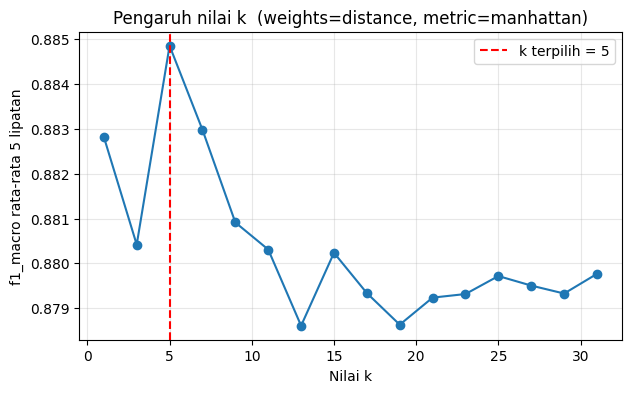

In [7]:
import matplotlib.pyplot as plt

w_menang = parameter_varian['weights']
m_menang = parameter_varian['metric']

baris = hasil[(hasil['param_model__weights'] == w_menang) &
              (hasil['param_model__metric'] == m_menang)]
baris = baris.sort_values('param_model__n_neighbors')

plt.figure(figsize=(7, 4))
plt.plot(baris['param_model__n_neighbors'], baris['mean_test_score'], marker='o')
plt.axvline(parameter_varian['n_neighbors'], color='red', linestyle='--',
            label=f"k terpilih = {parameter_varian['n_neighbors']}")
plt.xlabel('Nilai k')
plt.ylabel('f1_macro rata-rata 5 lipatan')
plt.title(f'Pengaruh nilai k  (weights={w_menang}, metric={m_menang})')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Bacalah grafik ini sebelum lanjut. Skor rendah pada k sangat kecil berarti model
mengikuti derau data latih; skor yang menurun pada k besar berarti batas keputusan
menjadi terlalu halus dan kelas minoritas mulai tertelan mayoritas. Posisi puncaknya
adalah k terpilih.

---
## Langkah 4 — Seberapa besar hasil penyetelan

Sel berikut membandingkan hasil Anda dengan Varian 1, bila berkasnya sudah ada. Bila
anggota 1 belum selesai, sel ini tetap berjalan dan hanya melewati perbandingannya.

In [8]:
jalur_v1 = os.path.join(FOLDER, 'varian1_knn_dasar.joblib')

if os.path.exists(jalur_v1):
    v1 = joblib.load(jalur_v1)
    if v1['kunci_data'] != KUNCI_DATA:
        print('PERHATIAN: kunci data Varian 1 berbeda dari kunci Anda.')
        print('  Varian 1 :', v1['kunci_data'])
        print('  Anda     :', KUNCI_DATA)
        print('Perbandingan di bawah tidak sah sampai keduanya memakai dasar yang sama.')
    rata_v1 = float(np.mean(v1['cv_lipatan']))
    beda = float(skor_varian.mean()) - rata_v1
    print('Varian 1 (k-NN dasar)     :', round(rata_v1, 4))
    print('Varian 2 (setelah setel)  :', round(float(skor_varian.mean()), 4))
    print('Kenaikan                  :', round(beda, 4))
    print()
    if beda < 0.01:
        print('Kenaikannya tipis. Itu temuan yang sah: pada data ini, menyetel')
        print('parameter k-NN hampir tidak menggeser kinerjanya. Tulis apa adanya.')
    else:
        print('Penyetelan memberi kenaikan yang terlihat. Sebutkan parameter mana')
        print('yang paling berperan menurut grafik Langkah 3.')
else:
    print('Berkas Varian 1 belum ada di folder proyek.')
    print('Perbandingannya nanti dikerjakan bersama di Pertemuan 13.')

Varian 1 (k-NN dasar)     : 0.8638
Varian 2 (setelah setel)  : 0.8849
Kenaikan                  : 0.021

Penyetelan memberi kenaikan yang terlihat. Sebutkan parameter mana
yang paling berperan menurut grafik Langkah 3.


---
## Langkah 5 — Model akhir varian ini

In [9]:
alur_akhir = cari.best_estimator_
print('Model Varian 2 sudah terlatih oleh GridSearchCV pada seluruh data latih.')
print('Parameter terpasang:', parameter_varian)

Model Varian 2 sudah terlatih oleh GridSearchCV pada seluruh data latih.
Parameter terpasang: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}


---
## Biaya komputasi varian ini

Waktu prediksi diukur pada 1.600 baris pertama data latih, bukan pada data uji.
Data uji sengaja belum dibuka sama sekali di notebook varian; pembukaannya satu
kali saja, di Pertemuan 13, setelah model terpilih ditetapkan. Ukuran berkas
model ikut dicatat karena layanan hosting gratis punya batas memori.

In [10]:
import tempfile

cuplik = X_train.head(1600)

mulai = time.perf_counter()
alur_akhir.predict(cuplik)
durasi_ms = (time.perf_counter() - mulai) * 1000

with tempfile.NamedTemporaryFile(suffix='.joblib', delete=False) as f:
    sementara = f.name
joblib.dump(alur_akhir, sementara)
ukuran_kb = os.path.getsize(sementara) / 1024
os.remove(sementara)

biaya_varian = {'prediksi_ms': round(durasi_ms, 1), 'ukuran_kb': round(ukuran_kb, 1)}
print('Waktu prediksi 1.600 baris :', biaya_varian['prediksi_ms'], 'ms')
print('Ukuran berkas model        :', biaya_varian['ukuran_kb'], 'KB')

Waktu prediksi 1.600 baris : 537.6 ms
Ukuran berkas model        : 3355.5 KB


---
## Langkah terakhir — Menyimpan hasil varian Anda

Berkas ini yang dibawa ke Pertemuan 13. Isinya model yang sudah terlatih, skor
tiap lipatan, biaya komputasi, nama Anda, dan kunci data. Kunci data itulah yang
diperiksa Pertemuan 13 untuk memastikan ketiga varian memakai pembagian yang sama.

In [11]:
if NAMA_ANGGOTA.startswith('tulis'):
    raise ValueError('Isi dulu NAMA_ANGGOTA di Langkah 1.')

hasil = {
    'nama_varian': NAMA_VARIAN,
    'nama_tampil': 'Varian 2 — penyetelan k-NN',
    'nama_anggota': NAMA_ANGGOTA,
    'model': alur_akhir,
    'parameter': parameter_varian,
    'cv_lipatan': [round(float(v), 4) for v in skor_varian],
    'biaya': biaya_varian,
    'kunci_data': KUNCI_DATA,
    'versi_sklearn': sklearn.__version__,
}

jalur_hasil = os.path.join(FOLDER, 'varian2_knn_setel.joblib')
joblib.dump(hasil, jalur_hasil)

print('Tersimpan :', jalur_hasil)
print('Ukuran    :', round(os.path.getsize(jalur_hasil) / 1024, 1), 'KB')
print('Pengerja  :', NAMA_ANGGOTA)
print('Rata-rata f1_macro :', round(float(np.mean(skor_varian)), 4))

Tersimpan : /content/drive/MyDrive/proyek_akhir_ml/varian2_knn_setel.joblib
Ukuran    : 3355.8 KB
Pengerja  : Nayla Rahma Farhanah
Rata-rata f1_macro : 0.8849


---
## Yang harus Anda tulis sendiri

**1. Parameter apa yang terpilih, dan apa arti tiap nilainya?** Jangan hanya menyalin
isi `best_params_`; jelaskan artinya satu per satu.

Parameter terbaiknya adalah n_neighbors = 5, weights = 'distance', dan metric = 'manhattan'. Artinya:   n_neighbors = 5: prediksi diambil dari suara 5 tetangga terdekat.weights = 'distance': tetangga yang jaraknya lebih dekat diberi bobot/suara lebih besar dibanding tetangga yang lebih jauh.metric = 'manhattan': jarak antar titik dihitung dengan menjumlahkan selisih absolut tiap fitur (menyusur sumbu), bukan garis lurus euclidean.

**2. Berapa kenaikan dari Varian 1, dan apakah kenaikan itu layak disebut berarti?**
Bandingkan besar kenaikannya dengan simpangan baku antar lipatan milik Anda.

Skor f1_macro naik +0,0211 (dari 0,8638 di Varian 1 menjadi 0,8849 di Varian 2). Kenaikan ini cukup berarti karena sekitar 2,7 kali simpangan baku antar lipatan Varian 2 (0,0079), jadi perbedaannya tidak sekadar tenggelam di dalam variasi antar lipatan.   

**3. Mengapa grafik Langkah 3 berbentuk seperti itu?** Jelaskan sisi kiri grafik
(k kecil) dan sisi kanannya (k besar) dengan alasan yang berbeda.

Pada sisi kiri (nilai k kecil, seperti k=1 atau k=3), skor belum di puncak karena keputusan terlalu bergantung pada tetangga paling dekat sehingga lebih sensitif terhadap derau (noise) data latih. Sebaliknya, pada sisi kanan (nilai k besar), skor cenderung turun karena jumlah tetangga terlalu banyak sehingga batas keputusan makin halus dan kelas minoritas berisiko kalah suara oleh kelas mayoritas, sementara puncak optimalnya tercapai di k = 5.

---
## Daftar periksa sebelum notebook ini ditutup

- [✔] Kunci data yang tercetak sama dengan kunci dua anggota lain
- [✔] `NAMA_ANGGOTA` sudah diisi nama Anda
- [✔] Parameter terbaik tercetak
- [✔] Lima skor lipatan tercetak
- [✔] Grafik pengaruh nilai k tampil dan puncaknya dapat ditunjuk
- [✔] Berkas `varian2_knn_setel.joblib` muncul di folder proyek
- [✔] Ketiga pertanyaan sudah dijawab, bukan masih berupa tanda kurung